## Introduction

<div class="slots">
<div class="slot"><span class="num">2.9m</span>copies for the median Zelda title, against 170,000 for all titles</div>
<div class="slot"><span class="num">34.1m</span>Breath of the Wild on Switch, the series record</div>
<div class="slot"><span class="num">46</span>Zelda copies per 100 Switch consoles sold</div>
<div class="slot"><span class="num">22 to 13</span>Japan's share of Zelda sales in percent, before and after 2006</div>
</div>

### Research question

**The Legend of Zelda** started on the Famicom Disk System in Japan on 21 February 1986. The latest original game, Echoes of Wisdom, came out on the Switch in September 2024. Nintendo has used Zelda to launch consoles twice: Twilight Princess shipped with the Wii in November 2006, and Breath of the Wild with the Switch on 3 March 2017.

So does Zelda sell the console? Answering that takes three steps. The first is to see how Zelda games sell next to the rest of Nintendo's catalogue and the wider industry, because a launch title only moves hardware if it sells well on its own. The second is to look at where Zelda copies are bought, since the series was born in Japan and may have drifted away from it. The third, and the one closest to the title, is to count how many Zelda copies sell for every console sold, and to see whether that number differs between home consoles and handhelds.

### Data

The project rests on three datasets. The main one is **VGChartz sales with Metacritic scores** (`data/raw/vgsales_2016.csv`), with 16,719 rows, one per title and platform, with estimated sales in North America, Europe, Japan and the rest of the world up to 22 December 2016. This is the Kaggle dataset "Video Game Sales with Ratings" (Kirubi 2016), downloaded from a GitHub mirror (`chahelgupta/DEP-videogames-dataset`).

Because VGChartz stops in 2016, the second source is **Nintendo's investor relations figures**. `data/raw/nintendo_platforms.csv` has lifetime hardware and software sales for 12 Nintendo consoles as of 30 June 2026. `data/raw/zelda_official_units.csv` adds six Zelda releases that VGChartz misses or undercounts: the five Switch games and The Wind Waker HD. Three of these come from Nintendo's top ten tables; the other three (Link's Awakening, Skyward Sword HD, Echoes of Wisdom) are Nintendo figures quoted on Wikipedia, because Nintendo only lists its top ten.

The third source is the **Metacritic record of the series** (`data/raw/zelda_reception.csv`), copied from the reception table on Wikipedia's Zelda page (as of 31 March 2025). They fill gaps in the VGChartz scores, mostly for the Nintendo 64 and Switch games.

::: {.callout-warning title="Attention" collapse="false"}
VGChartz numbers are estimates of boxed retail sales. They stop in December 2016 and leave out digital copies, so everything from 2017 on uses Nintendo's own figures. Charts that mix the two sources say so.
:::

### Setup

The setup cell loads the libraries and two fonts from `fonts/`: Fira Sans for the text and charts, and a Zelda style font for the title. It also sets one colour scheme for the whole notebook. Gold is always Zelda, green is the rest of Nintendo and grey is everyone else; for console types, green is home, gold is handheld and blue is hybrid. I avoided a red and green pair because it is the hardest one to tell apart for colour blind readers. A small helper, `frame()`, adds the same title and source line to every chart.

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import font_manager
from matplotlib.patches import Polygon, Rectangle
from scipy.stats import gaussian_kde
from scipy import ndimage
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
for path in glob.glob("fonts/*.ttf"):
    font_manager.fontManager.addfont(path)
plt.rcParams["font.family"] = "Fira Sans"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["figure.facecolor"] = "floralwhite"
plt.rcParams["axes.facecolor"] = "floralwhite"
plt.rcParams["savefig.facecolor"] = "floralwhite"
plt.rcParams["axes.edgecolor"] = "darkgray"
plt.rcParams["axes.labelcolor"] = "dimgray"
plt.rcParams["axes.labelsize"] = 9
plt.rcParams["text.color"] = "darkslategray"
plt.rcParams["xtick.color"] = "dimgray"
plt.rcParams["ytick.color"] = "dimgray"
plt.rcParams["xtick.labelsize"] = 8.5
plt.rcParams["ytick.labelsize"] = 8.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["legend.frameon"] = False
INK = "darkslategray"
ZELDA = "goldenrod"
NINTENDO = "seagreen"
OTHER = "silver"
TYPE_COLORS = {"Home": "seagreen", "Handheld": "goldenrod", "Hybrid": "slateblue"}
HYRULE = mcolors.LinearSegmentedColormap.from_list("hyrule", ["oldlace", "palegoldenrod", "goldenrod", "darkgoldenrod", "saddlebrown"])
SALES_TICKS = [0.01, 0.1, 1, 10, 80]
SALES_LABELS = ["10k", "100k", "1m", "10m", "80m"]
def frame(fig, title, subtitle, source, head=0.95, foot=0.4):
    h = fig.get_figheight()
    fig.text(0.012, 1 - 0.14 / h, title, fontsize=15, fontweight="bold", color=INK, va="top")
    head = 0.55
    fig.text(0.012, 0.1 / h, "Source: " + source, fontsize=7.5, color="gray", va="bottom", style="italic")
    fig.tight_layout(rect=[0, foot / h, 1, 1 - head / h])

## Data preparation

### Loading the sales file

In [2]:
games = pd.read_csv("data/raw/vgsales_2016.csv")
print(games.shape)
games.head(3)

(16719, 16)


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E


In [3]:
print(games[["Name", "Year_of_Release", "Publisher", "Critic_Score", "User_Score"]].isna().sum())
print((games["User_Score"] == "tbd").sum(), "user scores read 'tbd'")
print(games[games["Year_of_Release"] > 2016][["Name", "Platform", "Year_of_Release"]])
print(games[games["Name"].str.contains("weekly", na=False)][["Name", "Platform", "Global_Sales"]])
games[games.duplicated(subset=["Name", "Platform", "Year_of_Release"], keep=False)][["Name", "Platform", "Year_of_Release", "Global_Sales"]]

Name                  2
Year_of_Release     269
Publisher            54
Critic_Score       8582
User_Score         6704
dtype: int64
2425 user scores read 'tbd'
                                                   Name Platform  Year_of_Release
5936                             Imagine: Makeup Artist       DS           2020.0
14086  Phantasy Star Online 2 Episode 4: Deluxe Package      PS4           2017.0
16222  Phantasy Star Online 2 Episode 4: Deluxe Package      PSV           2017.0
16385                  Brothers Conflict: Precious Baby      PSV           2017.0
                                                    Name Platform  Global_Sales
788              Project Gotham Racing (JP weekly sales)       XB          2.10
1534   Midnight Club 3: DUB Edition (America weekly s...      PS2          1.29
1815   Pokémon Mystery Dungeon: Red Rescue Team (US w...      GBA          1.13
6165        The Urbz: Sims In the City (US weekly sales)       DS          0.28
6256   The Legend of Zelda: T

,Name,Platform,Year_of_Release,Global_Sales
604,Madden NFL 13,PS3,2012.0,2.56
659,NaN,GEN,1993.0,2.39
14246,NaN,GEN,1993.0,0.03
16233,Madden NFL 13,PS3,2012.0,0.01


A first look turns up a few problems. Two rows have no name, 2,425 user scores are the text "tbd", four rows are dated after the December 2016 snapshot (one says 2020), and some rows only cover a few weeks of sales in one country, like "The Legend of Zelda: The Minish Cap(weekly JP sales)". Madden NFL 13 on PS3 is listed twice.

### Cleaning

I drop the rows with no name, the 20 partial weekly rows, the duplicate (keeping the bigger number) and the four rows from after the snapshot. "tbd" becomes a missing value so user scores can be numeric. I also fix one date by hand: VGChartz puts Link's Awakening on the Game Boy in 1992, but it came out in June 1993.

In [4]:
start = len(games)
games = games.dropna(subset=["Name"])
print(start - len(games), "rows without a name dropped")
n = len(games)
games = games[~games["Name"].str.contains("weekly", case=False)]
print(n - len(games), "partial 'weekly sales' rows dropped")
n = len(games)
games = games.sort_values("Global_Sales", ascending=False)
games = games.drop_duplicates(subset=["Name", "Platform", "Year_of_Release"], keep="first")
print(n - len(games), "duplicate row dropped")
n = len(games)
games = games[~(games["Year_of_Release"] > 2016)]
print(n - len(games), "rows dated after the December 2016 snapshot dropped")
games.loc[(games["Name"] == "The Legend of Zelda: Link's Awakening") & (games["Platform"] == "GB"), "Year_of_Release"] = 1993
print("Link's Awakening (GB) moved from 1992 to its 1993 release year")
games["User_Score"] = pd.to_numeric(games["User_Score"].replace("tbd", np.nan))
games.columns = games.columns.str.lower()
games = games.rename(columns={"year_of_release": "year"})
games["year"] = games["year"].astype("Int64")
print(games.shape)

2 rows without a name dropped
20 partial 'weekly sales' rows dropped
1 duplicate row dropped
4 rows dated after the December 2016 snapshot dropped
Link's Awakening (GB) moved from 1992 to its 1993 release year
(16692, 16)


### Tagging Nintendo franchises

A title counts toward a franchise if Nintendo published it and the franchise name is in the title. Mario is checked last, so "Mario vs. Donkey Kong" counts as Mario, and Sega's Mario and Sonic games stay out because Sega published them. This rule also leaves out Zelda spin offs without "Zelda" in the name, such as Hyrule Warriors. A second column, `group`, sorts everything into Zelda, other Nintendo and other publishers.

In [5]:
games["nintendo"] = games["publisher"] == "Nintendo"
patterns = {"Pokemon": "Pok", "Donkey Kong": "Donkey Kong", "Kirby": "Kirby", "Metroid": "Metroid", "Fire Emblem": "Fire Emblem", "Animal Crossing": "Animal Crossing", "Smash Bros.": "Smash Bros", "Mario": "Mario", "Zelda": "Zelda"}
games["franchise"] = np.where(games["nintendo"], "Other Nintendo", "Other publishers")
for name, pattern in patterns.items():
    games.loc[games["nintendo"] & games["name"].str.contains(pattern), "franchise"] = name
games["group"] = games["franchise"].where(games["franchise"].isin(["Zelda", "Other publishers"]), "Other Nintendo")
games.groupby("franchise").agg(titles=("name", "count"), units_m=("global_sales", "sum")).sort_values("units_m", ascending=False).round(1)

,titles,units_m
franchise,,
Other publishers,15989,7119.4
Other Nintendo,432,726.2
Mario,106,526.9
Pokemon,49,258.0
Zelda,26,82.2
Donkey Kong,27,59.1
Smash Bros.,5,37.9
Kirby,24,37.1
Animal Crossing,6,32.5


### Building the Zelda table

The franchise tag gives 26 Zelda rows. VGChartz files The Wind Waker HD under the GameCube title, so I rename it to match Nintendo's list.

In [6]:
zelda = games[games["franchise"] == "Zelda"][["name", "platform", "year", "global_sales", "na_sales", "eu_sales", "jp_sales", "other_sales", "critic_score"]].copy()
zelda = zelda.rename(columns={"name": "title", "platform": "code", "global_sales": "units_m"})
zelda.loc[(zelda["title"] == "The Legend of Zelda: The Wind Waker") & (zelda["code"] == "WiiU"), "title"] = "The Legend of Zelda: The Wind Waker HD"
zelda["source"] = "VGChartz estimate (Dec 2016)"
print(len(zelda), "Zelda titles in the VGChartz file")
zelda.sort_values("year").head(8)

26 Zelda titles in the VGChartz file


,title,code,year,units_m,na_sales,eu_sales,jp_sales,other_sales,critic_score,source
124,The Legend of Zelda,NES,1986,6.51,3.74,0.93,1.69,0.14,NaN,VGChartz estimate (Dec 2016)
252,Zelda II: The Adventure of Link,NES,1987,4.38,2.19,0.50,1.61,0.08,NaN,VGChartz estimate (Dec 2016)
232,The Legend of Zelda: A Link to the Past,SNES,1991,4.61,2.42,0.91,1.15,0.13,NaN,VGChartz estimate (Dec 2016)
322,The Legend of Zelda: Link's Awakening,GB,1993,3.83,2.21,0.96,0.54,0.13,NaN,VGChartz estimate (Dec 2016)
731,The Legend of Zelda: Link's Awakening DX,GB,1998,2.22,1.00,0.63,0.45,0.13,NaN,VGChartz estimate (Dec 2016)
93,The Legend of Zelda: Ocarina of Time,N64,1998,7.60,4.10,1.89,1.45,0.16,NaN,VGChartz estimate (Dec 2016)
400,The Legend of Zelda: Majora's Mask,N64,2000,3.36,1.90,0.67,0.73,0.06,NaN,VGChartz estimate (Dec 2016)
897,The Legend of Zelda: Oracle of Ages,GB,2001,1.92,0.92,0.53,0.41,0.06,NaN,VGChartz estimate (Dec 2016)


### Adding Nintendo's figures

The Wind Waker HD is a good check on VGChartz: 1.79 million estimated, 2.37 million according to Nintendo, about 32 percent more. I replace the estimate with Nintendo's number and add the five Switch games with `pd.concat`, which gives 31 releases. Since VGChartz misses digital sales, the pre 2017 numbers are probably on the low side.

In [7]:
official = pd.read_csv("data/raw/zelda_official_units.csv")
check = zelda[zelda["title"] == "The Legend of Zelda: The Wind Waker HD"][["title", "units_m"]]
check = check.merge(official[["title", "units_m"]], on="title", suffixes=("_vgchartz", "_nintendo"))
print(check)
zelda = zelda[zelda["title"] != "The Legend of Zelda: The Wind Waker HD"]
zelda = pd.concat([zelda, official[["title", "code", "year", "units_m", "source"]]], ignore_index=True)
zelda["year"] = zelda["year"].astype(int)
print(len(zelda), "Zelda releases after appending the Nintendo figures")
official

                                    title  units_m_vgchartz  units_m_nintendo
0  The Legend of Zelda: The Wind Waker HD              1.79              2.37
31 Zelda releases after appending the Nintendo figures


,title,code,year,units_m,as_of,source
0,The Legend of Zelda: Breath of the Wild,NS,2017,34.06,2026-06-30,Nintendo IR top selling titles (Switch)
1,The Legend of Zelda: Tears of the Kingdom,NS,2023,22.71,2026-06-30,Nintendo IR top selling titles (Switch)
2,The Legend of Zelda: Link's Awakening,NS,2019,6.46,2022-12-31,Nintendo results briefing via Wikipedia
3,The Legend of Zelda: Skyward Sword HD,NS,2021,4.15,NaN,Nintendo via Wikipedia (date not given)
4,The Legend of Zelda: Echoes of Wisdom,NS,2024,4.09,2025-03-31,Nintendo results briefing via Wikipedia
5,The Legend of Zelda: The Wind Waker HD,WiiU,2013,2.37,2026-03-31,Nintendo IR top selling titles (Wii U)


### Joining critic scores

Only 15 of the VGChartz Zelda rows have a Metacritic score. I join the Wikipedia scores on game name and platform, after stripping "The Legend of Zelda: ", " HD" and " 3D" so the names match. On the 15 rows where both sources have a score, they agree every time, which is a good sign the join worked. The seven releases left without a score are NES, SNES and Game Boy games that Metacritic never rated.

In [8]:
reception = pd.read_csv("data/raw/zelda_reception.csv")
zelda["game"] = zelda["title"].str.replace("Classic NES Series: ", "")
zelda["game"] = zelda["game"].str.replace("The Legend of Zelda: ", "")
zelda["game"] = zelda["game"].str.replace("Zelda II: ", "")
zelda["game"] = zelda["game"].str.replace(" 3D", "").str.replace(" HD", "").str.replace(" DX", "")
zelda = zelda.merge(reception, on=["game", "code"], how="left")
both = zelda.dropna(subset=["critic_score", "metacritic"])
print(len(both), "rows have both scores;", (both["critic_score"] != both["metacritic"]).sum(), "disagree")
zelda["score"] = zelda["critic_score"].fillna(zelda["metacritic"])
print(zelda["score"].notna().sum(), "of", len(zelda), "releases now carry a Metacritic score")

15 rows have both scores; 0 disagree
24 of 31 releases now carry a Metacritic score


### Remakes and console type

Each release is marked as an original or a remake/port, and a join with the platform table adds the console type and Nintendo's lifetime hardware sales. Twilight Princess counts twice as an original because it came out on both the Wii and the GameCube.

In [9]:
remakes = ["Classic NES", " 3D", " HD", " DX", "Ocarina of Time"]
zelda["kind"] = "Original"
for word in remakes:
    zelda.loc[zelda["title"].str.contains(word), "kind"] = "Remake or port"
zelda.loc[(zelda["title"] == "The Legend of Zelda: Ocarina of Time") & (zelda["code"] == "N64"), "kind"] = "Original"
zelda.loc[(zelda["title"] == "The Legend of Zelda: A Link to the Past") & (zelda["code"] == "GBA"), "kind"] = "Remake or port"
zelda.loc[(zelda["title"] == "The Legend of Zelda: Link's Awakening") & (zelda["code"] == "NS"), "kind"] = "Remake or port"
platforms = pd.read_csv("data/raw/nintendo_platforms.csv")
zelda = zelda.merge(platforms[["code", "type", "hardware_m"]], on="code", how="left")
zelda = zelda.sort_values(["year", "units_m"], ascending=[True, False]).reset_index(drop=True)
zelda[["title", "code", "year", "kind", "type", "units_m", "score", "source"]]

,title,code,year,kind,type,units_m,score,source
0,The Legend of Zelda,NES,1986,Original,Home,6.51,NaN,VGChartz estimate (Dec 2016)
1,Zelda II: The Adventure of Link,NES,1987,Original,Home,4.38,NaN,VGChartz estimate (Dec 2016)
2,The Legend of Zelda: A Link to the Past,SNES,1991,Original,Home,4.61,NaN,VGChartz estimate (Dec 2016)
3,The Legend of Zelda: Link's Awakening,GB,1993,Original,Handheld,3.83,NaN,VGChartz estimate (Dec 2016)
4,The Legend of Zelda: Ocarina of Time,N64,1998,Original,Home,7.60,99.0,VGChartz estimate (Dec 2016)
5,The Legend of Zelda: Link's Awakening DX,GB,1998,Remake or port,Handheld,2.22,NaN,VGChartz estimate (Dec 2016)
6,The Legend of Zelda: Majora's Mask,N64,2000,Original,Home,3.36,95.0,VGChartz estimate (Dec 2016)
7,The Legend of Zelda: Oracle of Ages,GB,2001,Original,Handheld,1.92,NaN,VGChartz estimate (Dec 2016)
8,The Legend of Zelda: Oracle of Seasons,GB,2001,Original,Handheld,1.86,NaN,VGChartz estimate (Dec 2016)
9,The Legend of Zelda: The Wind Waker,GC,2002,Original,Home,4.60,96.0,VGChartz estimate (Dec 2016)


### Data dictionary

The table below lists every column in the final Zelda table, with its unit and how many of the 31 rows have a value. The regional columns are empty for the six Nintendo rows, because Nintendo only reports worldwide totals.

In [10]:
pd.set_option("display.max_colwidth", 90)
notes = {
    "title": ("text", "", "Title as published; remakes keep their own title"),
    "code": ("text", "", "Platform code shared by all three datasets"),
    "year": ("integer", "year", "Release year (Link's Awakening corrected to 1993)"),
    "units_m": ("float", "million copies", "Life to date sales, VGChartz estimate or Nintendo figure"),
    "na_sales": ("float", "million copies", "North America, VGChartz rows only"),
    "eu_sales": ("float", "million copies", "Europe, VGChartz rows only"),
    "jp_sales": ("float", "million copies", "Japan, VGChartz rows only"),
    "other_sales": ("float", "million copies", "Rest of world, VGChartz rows only"),
    "critic_score": ("float", "0 to 100", "Metacritic score as stored in the VGChartz file"),
    "source": ("text", "", "Which dataset the sales figure comes from"),
    "game": ("text", "", "Short name used to join the Wikipedia score table"),
    "metacritic": ("float", "0 to 100", "Metacritic score from the Wikipedia table"),
    "score": ("float", "0 to 100", "critic_score, filled from metacritic where missing"),
    "kind": ("text", "", "Original or remake/port"),
    "type": ("text", "", "Home, handheld or hybrid console, from the platform table"),
    "hardware_m": ("float", "million consoles", "Nintendo life to date hardware sales, 30 June 2026"),
}
dictionary = pd.DataFrame([(col, kind, unit, text, zelda[col].notna().sum()) for col, (kind, unit, text) in notes.items()], columns=["column", "type", "unit", "meaning", "non_missing"])
print(len(zelda), "rows,", len(zelda.columns), "columns")
dictionary

31 rows, 16 columns


,column,type,unit,meaning,non_missing
0,title,text,,Title as published; remakes keep their own title,31
1,code,text,,Platform code shared by all three datasets,31
2,year,integer,year,Release year (Link's Awakening corrected to 1993),31
3,units_m,float,million copies,"Life to date sales, VGChartz estimate or Nintendo figure",31
4,na_sales,float,million copies,"North America, VGChartz rows only",25
5,eu_sales,float,million copies,"Europe, VGChartz rows only",25
6,jp_sales,float,million copies,"Japan, VGChartz rows only",25
7,other_sales,float,million copies,"Rest of world, VGChartz rows only",25
8,critic_score,float,0 to 100,Metacritic score as stored in the VGChartz file,15
9,source,text,,Which dataset the sales figure comes from,31


## How Zelda sells

### Forty years of Zelda

Every release by year and copies sold, with Nintendo's home console generations shaded behind.

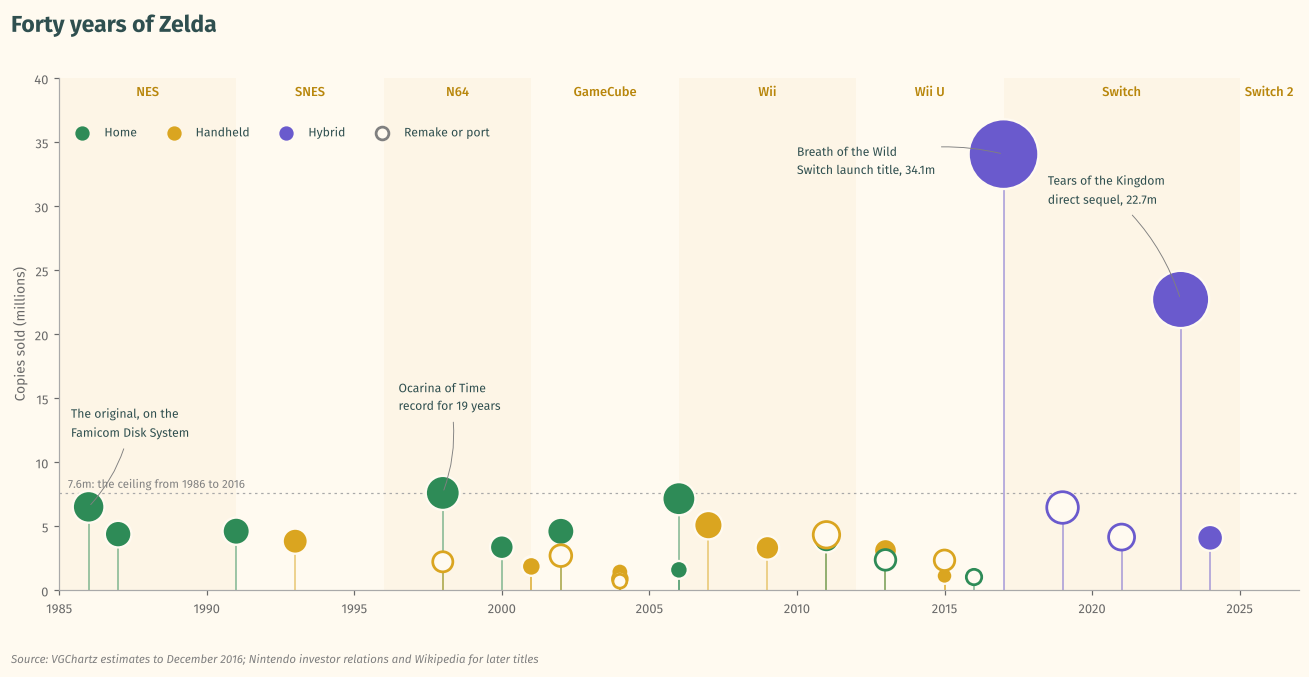

In [11]:
#| label: fig-timeline
#| fig-cap: "**Forty years of Zelda.** 31 releases, 1986 to 2024. VGChartz estimates to December 2016, Nintendo figures after; remakes hollow."
gens = [(1985, "NES"), (1991, "SNES"), (1996, "N64"), (2001, "GameCube"), (2006, "Wii"), (2012, "Wii U"), (2017, "Switch"), (2025, "Switch 2")]
fig, ax = plt.subplots(figsize=(12, 6.2))
for i, (start, name) in enumerate(gens):
    end = gens[i + 1][0] if i + 1 < len(gens) else 2027
    ax.axvspan(start, end, color="oldlace" if i % 2 == 0 else "floralwhite", zorder=0, linewidth=0)
    ax.text((start + end) / 2, 38.6, name, ha="center", fontsize=8.5, color="darkgoldenrod", fontweight="medium")
ax.vlines(zelda["year"], 0, zelda["units_m"], color=zelda["type"].map(TYPE_COLORS), linewidth=1.2, alpha=0.5, zorder=2)
orig = zelda[zelda["kind"] == "Original"]
port = zelda[zelda["kind"] != "Original"]
ax.scatter(orig["year"], orig["units_m"], s=orig["units_m"] * 60 + 40, color=orig["type"].map(TYPE_COLORS), edgecolor="floralwhite", linewidth=1.5, zorder=3)
ax.scatter(port["year"], port["units_m"], s=port["units_m"] * 60 + 40, facecolor="floralwhite", edgecolor=port["type"].map(TYPE_COLORS), linewidth=1.8, zorder=3)
notes = {("The Legend of Zelda", "NES"): (-0.6, 5, "The original, on the\nFamicom Disk System"), ("The Legend of Zelda: Ocarina of Time", "N64"): (-1.5, 6, "Ocarina of Time\nrecord for 19 years"), ("The Legend of Zelda: Breath of the Wild", "NS"): (-7, -2, "Breath of the Wild\nSwitch launch title, 34.1m"), ("The Legend of Zelda: Tears of the Kingdom", "NS"): (-4.5, 7, "Tears of the Kingdom\ndirect sequel, 22.7m")}
for row in zelda.itertuples():
    key = (row.title, row.code)
    if key in notes:
        dx, dy, text = notes[key]
        ax.annotate(text, (row.year, row.units_m), xytext=(row.year + dx, row.units_m + dy), fontsize=8, color=INK, ha="left", va="bottom", linespacing=1.3, arrowprops=dict(arrowstyle="-", color="gray", linewidth=0.6, connectionstyle="arc3,rad=-0.15"))
ax.axhline(7.6, color="darkgray", linestyle=(0, (2, 3)), linewidth=0.8, zorder=1)
ax.text(1985.3, 8, "7.6m: the ceiling from 1986 to 2016", fontsize=7.5, color="gray")
ax.set_xlim(1985, 2027)
ax.set_ylim(0, 40)
ax.set_ylabel("Copies sold (millions)")
for name, color in TYPE_COLORS.items():
    ax.scatter([], [], s=70, color=color, label=name)
ax.scatter([], [], s=70, facecolor="floralwhite", edgecolor="gray", linewidth=1.8, label="Remake or port")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.93), fontsize=8, ncol=4)
frame(fig, "Forty years of Zelda", "Every release in the data, by year and copies sold. Bands mark Nintendo's home console generations.", "VGChartz estimates to December 2016; Nintendo investor relations and Wikipedia for later titles")
plt.show()

For thirty years Zelda sold in a narrow range. Every original from 1986 to 2015 sold between 0.8 and 7.6 million copies, and Ocarina of Time held the record for nineteen years. Then Breath of the Wild sold 34.1 million on the Switch, about four and a half times the old record, and Tears of the Kingdom added 22.7 million. Echoes of Wisdom, a smaller top down game, went back to 4.1 million.

### Zelda against the industry

Game sales are very right skewed: a handful of games sell tens of millions and most sell very little. I use a log scale and draw one density ridge per Nintendo franchise, with all other publishers at the bottom. Each ridge is scaled to the same height, so compare where they sit, not how big they look.

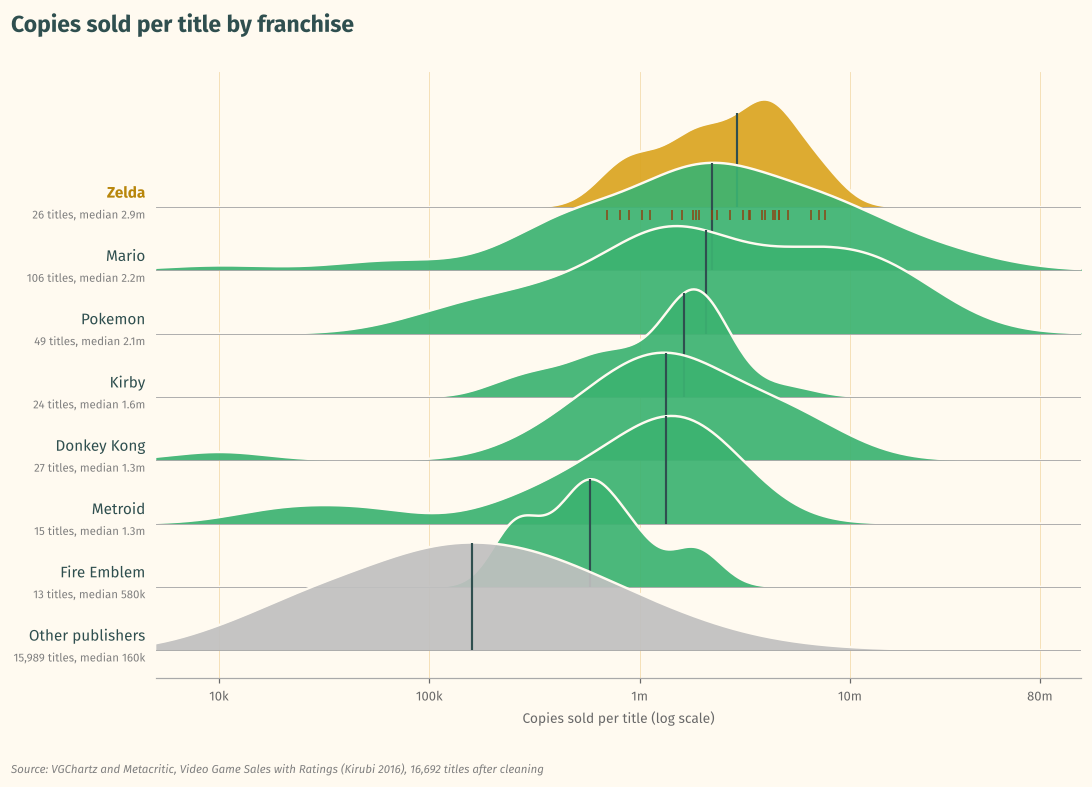

In [12]:
#| label: fig-ridge
#| fig-cap: "**Sales by franchise.** Kernel density of copies per title on a log scale (bandwidth 0.4), with group sizes printed. Small groups such as Fire Emblem (13 titles) give rough curves."
sold = games[games["global_sales"] > 0]
ridge_names = ["Other publishers", "Fire Emblem", "Metroid", "Kirby", "Donkey Kong", "Mario", "Pokemon", "Zelda"]
medians = {name: sold.loc[sold["franchise"] == name, "global_sales"].median() for name in ridge_names}
ridge_names = sorted(ridge_names, key=lambda name: medians[name])
xs = np.linspace(-2.3, 2.1, 400)
fig, ax = plt.subplots(figsize=(10, 7.2))
for i, name in enumerate(ridge_names):
    vals = np.log10(sold.loc[sold["franchise"] == name, "global_sales"])
    dens = gaussian_kde(vals, bw_method=0.4)(xs)
    dens = dens / dens.max() * 1.7
    color = ZELDA if name == "Zelda" else (OTHER if name == "Other publishers" else "mediumseagreen")
    ax.fill_between(xs, i, i + dens, color=color, alpha=0.92, zorder=20 - i, linewidth=0)
    ax.plot(xs, i + dens, color="floralwhite", linewidth=1.6, zorder=20 - i)
    ax.plot(xs, np.full(len(xs), i), color="darkgray", linewidth=0.6, zorder=20 - i)
    m = np.log10(medians[name])
    ax.vlines(m, i, i + np.interp(m, xs, dens), color=INK, linewidth=1.4, zorder=20 - i)
    ax.text(-2.35, i + 0.15, name, ha="right", fontsize=10, fontweight="bold" if name == "Zelda" else "normal", color="darkgoldenrod" if name == "Zelda" else INK)
    ax.text(-2.35, i - 0.18, f"{len(vals):,} titles, median {medians[name] * 1000:,.0f}k" if medians[name] < 1 else f"{len(vals):,} titles, median {medians[name]:.1f}m", ha="right", fontsize=7.5, color="gray")
z = np.log10(sold.loc[sold["franchise"] == "Zelda", "global_sales"])
ax.plot(z, np.full(len(z), len(ridge_names) - 1 - 0.12), "|", color="saddlebrown", markersize=7, zorder=30)
ax.set_xticks(np.log10(SALES_TICKS))
ax.set_xticklabels(SALES_LABELS)
ax.set_xlim(-2.3, 2.1)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("Copies sold per title (log scale)")
ax.grid(axis="x", color="wheat", linewidth=0.6)
ax.set_axisbelow(True)
frame(fig, "Copies sold per title by franchise", "Density of copies sold per title, one ridge per Nintendo franchise, against all other publishers. Black ticks are medians; brown ticks are Zelda titles.", "VGChartz and Metacritic, Video Game Sales with Ratings (Kirubi 2016), 16,692 titles after cleaning", head=1.05)
plt.show()

The median game from other publishers sold 160,000 copies. Even Fire Emblem, the smallest franchise here, has a median of 580,000. Zelda has the highest median, 2.9 million, ahead of Mario (2.2 million) and Pokemon (2.1 million). Its lowest title, the GBA port of Zelda II, still sold 700,000. Mario and Pokemon have bigger hits, but they also put out many small spin offs that pull their medians down.

### How certain are the medians?

A median from 26 games is not exact. To get a sense of the uncertainty I bootstrap it: resample each group's games 4,000 times, take the median each time, and keep the middle 95 percent. The seed is fixed so the result is the same on every run.

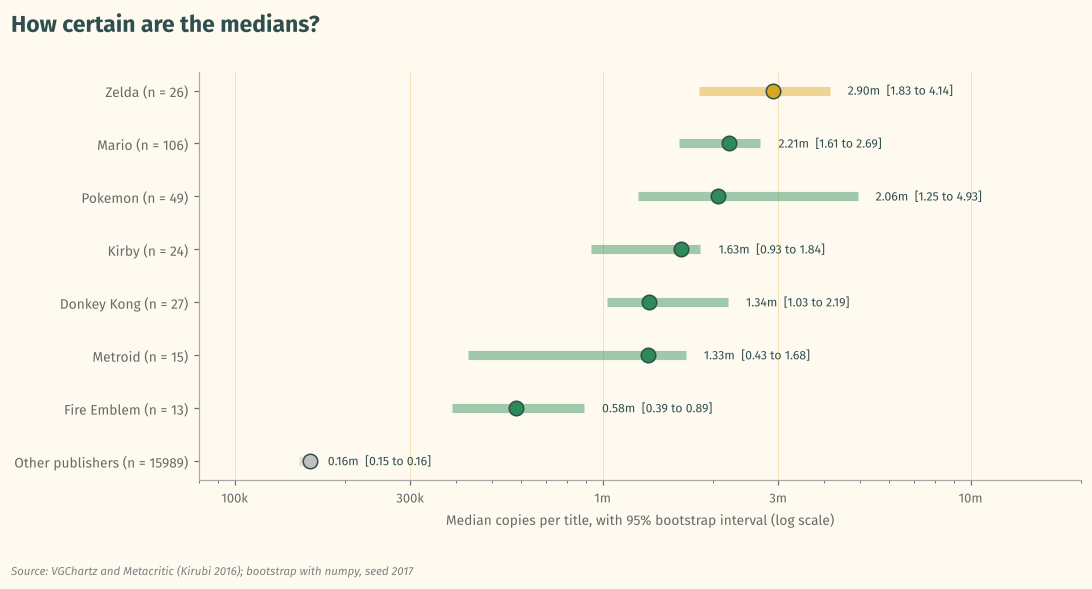

,group,n,median,low,high
0,Other publishers,15989,0.16,0.15,0.16
1,Fire Emblem,13,0.58,0.39,0.89
2,Metroid,15,1.33,0.43,1.68
3,Donkey Kong,27,1.34,1.03,2.19
4,Kirby,24,1.63,0.93,1.84
5,Pokemon,49,2.06,1.25,4.93
6,Mario,106,2.21,1.61,2.68
7,Zelda,26,2.90,1.83,4.14


In [13]:
#| label: fig-shrine
#| fig-cap: "**Uncertainty in the medians.** Median copies per title with 95 percent bootstrap intervals from 4,000 resamples."
rng = np.random.default_rng(2017)
groups = ["Zelda", "Mario", "Pokemon", "Kirby", "Donkey Kong", "Metroid", "Fire Emblem", "Other publishers"]
rows = []
for name in groups:
    values = sold.loc[sold["franchise"] == name, "global_sales"].values
    draws = rng.choice(values, size=(4000, len(values)), replace=True)
    medians = np.median(draws, axis=1)
    rows.append((name, len(values), np.median(values), np.percentile(medians, 2.5), np.percentile(medians, 97.5)))
boot = pd.DataFrame(rows, columns=["group", "n", "median", "low", "high"]).sort_values("median").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5.4))
for i, row in boot.iterrows():
    color = ZELDA if row["group"] == "Zelda" else (OTHER if row["group"] == "Other publishers" else NINTENDO)
    ax.hlines(i, row["low"], row["high"], color=color, linewidth=6, alpha=0.45)
    ax.scatter(row["median"], i, s=90, color=color, edgecolor=INK, linewidth=1, zorder=3)
    ax.text(row["high"] * 1.12, i, f"{row['median']:.2f}m  [{row['low']:.2f} to {row['high']:.2f}]", va="center", fontsize=8, color=INK)
ax.set_yticks(boot.index)
ax.set_yticklabels(boot["group"] + " (n = " + boot["n"].astype(str) + ")", fontsize=9)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.3, 1, 3, 10])
ax.set_xticklabels(["100k", "300k", "1m", "3m", "10m"])
ax.set_xlim(0.08, 20)
ax.set_xlabel("Median copies per title, with 95% bootstrap interval (log scale)")
ax.grid(axis="x", color="wheat", linewidth=0.6)
ax.set_axisbelow(True)
frame(fig, "How certain are the medians?", "Median copies per title by group. Bars span the middle 95 percent of 4,000 bootstrap medians.", "VGChartz and Metacritic (Kirubi 2016); bootstrap with numpy, seed 2017")
plt.show()
boot.round(2)

Zelda's interval runs from 1.83 to 4.14 million. It overlaps with Mario (1.61 to 2.69) and Pokemon (1.25 to 4.93), so I can't say Zelda's median is higher than theirs. All three are clearly above Fire Emblem (0.39 to 0.89) and other publishers (0.16).

The skew also shows up in the means. Other publishers average 0.45 million per game, almost three times their median, because a few hits pull the average up. Zelda's mean (3.16 million) is close to its median, since the series has no long tail of small games.

### Critic scores

Metacritic scores for 8,136 titles. Each group gets a density curve, a bar for the middle 50 percent with the median as a white dot, and every title as a dot underneath.

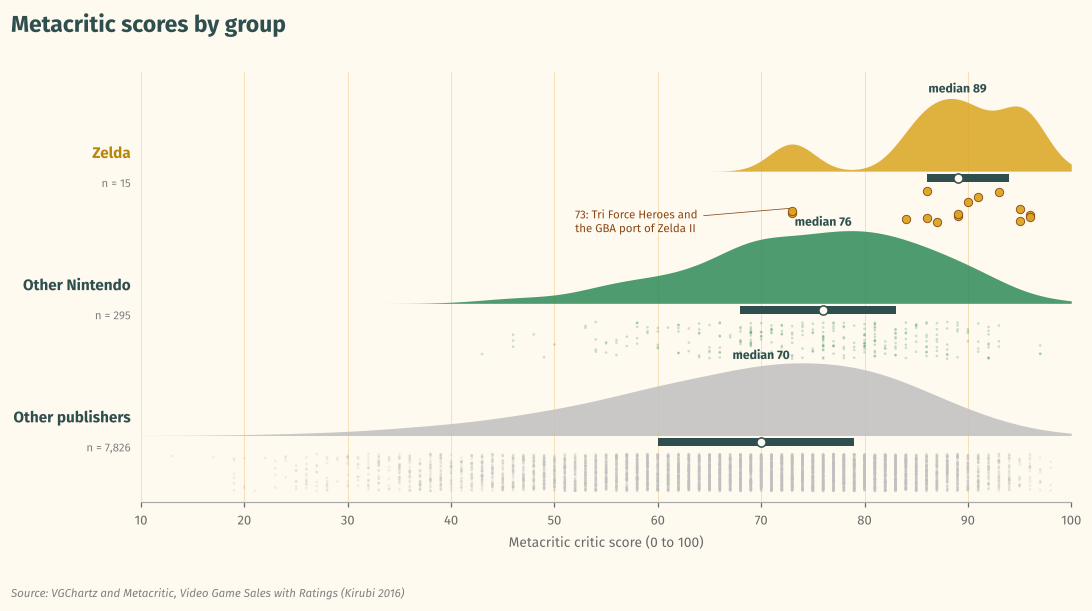

In [14]:
#| label: fig-rain
#| fig-cap: "**Critic scores.** Metacritic scores for 8,136 titles; only 15 Zelda titles are scored in this file."
scored = games.dropna(subset=["critic_score"])
order = ["Other publishers", "Other Nintendo", "Zelda"]
colors = {"Other publishers": OTHER, "Other Nintendo": NINTENDO, "Zelda": ZELDA}
grid = np.linspace(10, 100, 300)
rng = np.random.default_rng(7)
fig, ax = plt.subplots(figsize=(10, 5.6))
for i, name in enumerate(order):
    vals = scored.loc[scored["group"] == name, "critic_score"]
    dens = gaussian_kde(vals, bw_method=0.3)(grid)
    dens = dens / dens.max() * 0.55
    ax.fill_between(grid, i, i + dens, color=colors[name], alpha=0.85, linewidth=0)
    q1, med, q3 = vals.quantile([0.25, 0.5, 0.75])
    ax.add_patch(Rectangle((q1, i - 0.08), q3 - q1, 0.06, facecolor=INK, edgecolor="none"))
    ax.scatter(med, i - 0.05, s=36, color="floralwhite", edgecolor=INK, zorder=4)
    ax.text(med, i + np.interp(med, grid, dens) + 0.05, f"median {med:.0f}", ha="center", fontsize=8, color=INK, fontweight="bold")
    jitter = rng.uniform(-0.42, -0.14, len(vals))
    size = 30 if name == "Zelda" else 3
    alpha = 0.95 if name == "Zelda" else 0.25
    ax.scatter(vals, i + jitter, s=size, color=colors[name], alpha=alpha, edgecolor="saddlebrown" if name == "Zelda" else "none", linewidth=0.6)
    ax.text(9, i + 0.1, name, ha="right", fontsize=10, fontweight="bold", color="darkgoldenrod" if name == "Zelda" else INK)
    ax.text(9, i - 0.12, f"n = {len(vals):,}", ha="right", fontsize=7.5, color="gray")
ax.annotate("73: Tri Force Heroes and\nthe GBA port of Zelda II", (73, 1.72), xytext=(52, 1.62), fontsize=7.5, color="saddlebrown", va="center", arrowprops=dict(arrowstyle="-", color="saddlebrown", linewidth=0.5))
ax.set_xlim(10, 100)
ax.set_ylim(-0.5, 2.75)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("Metacritic critic score (0 to 100)")
ax.grid(axis="x", color="wheat", linewidth=0.6)
ax.set_axisbelow(True)
frame(fig, "Metacritic scores by group", "Raincloud plot of Metacritic scores: density on top, interquartile range as a bar, every scored title as a dot below.", "VGChartz and Metacritic, Video Game Sales with Ratings (Kirubi 2016)")
plt.show()

The median Zelda score is 89, against 76 for other Nintendo games and 70 for everyone else. The two lowest Zelda scores, both 73, are Tri Force Heroes and the GBA port of Zelda II, and even those beat the industry median. Only 15 Zelda games have a score in this file, so the Zelda curve is rough; the dots underneath show what it is built on.

### Scores as heart containers

Each original game gets ten hearts, one per 10 Metacritic points, filled left to right in quarters like the health bar in the games. A score of 87 is eight full hearts and three quarters of the ninth. The bar on the right is copies sold. Six originals have no score: the NES, SNES and Game Boy games and the two Oracle games.

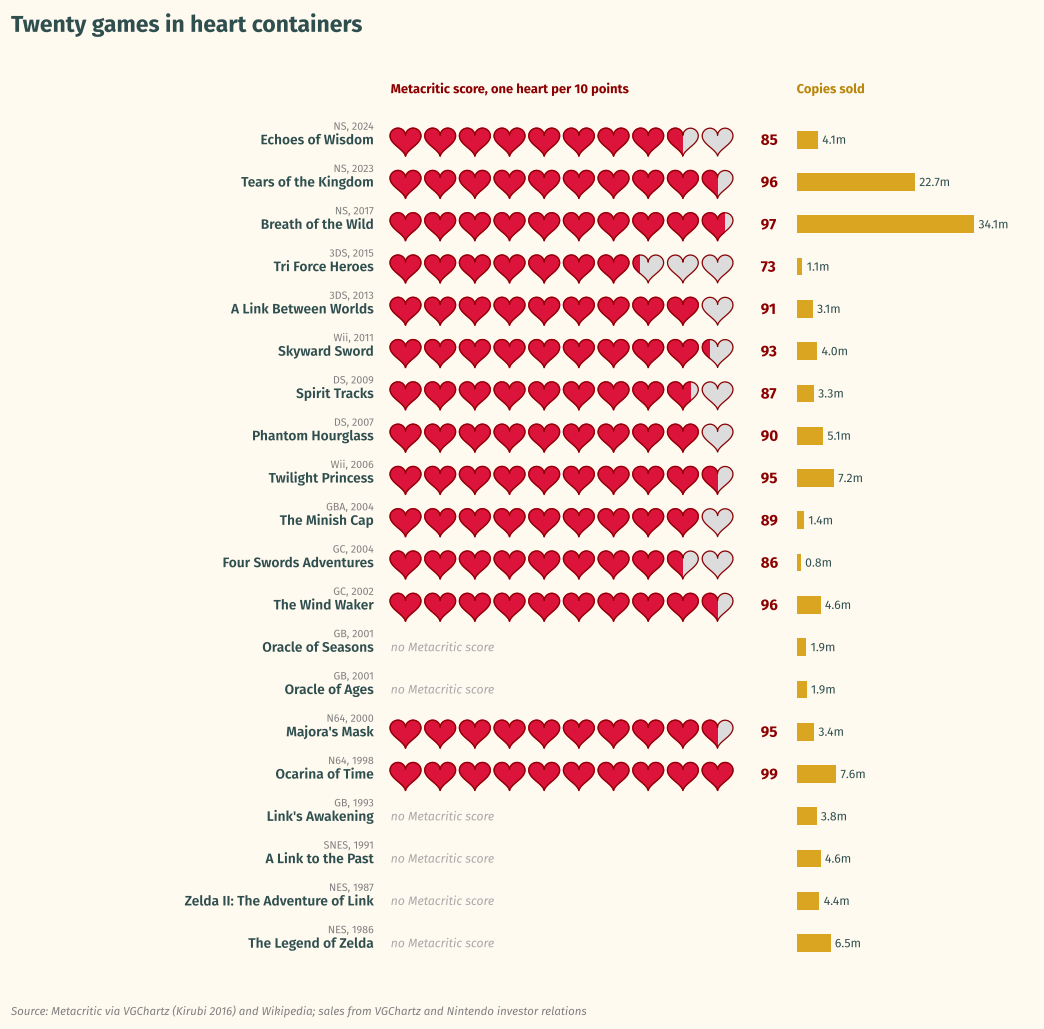

In [15]:
#| label: fig-hearts
#| fig-cap: "**Heart containers.** 20 original games, 14 of them with a Metacritic score; one heart is 10 points."
t = np.linspace(0, 2 * np.pi, 120)
heart_x = 16 * np.sin(t) ** 3 / 44
heart_y = (13 * np.cos(t) - 5 * np.cos(2 * t) - 2 * np.cos(3 * t) - np.cos(4 * t)) / 44
games_h = zelda[zelda["kind"] == "Original"].drop_duplicates(subset="title").sort_values("year", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10.5, 9.4))
for i, row in games_h.iterrows():
    short = row["title"].replace("The Legend of Zelda: ", "")
    ax.text(-0.4, i, short, ha="right", va="center", fontsize=9, color=INK, fontweight="semibold")
    ax.text(-0.4, i - 0.32, f"{row['code']}, {row['year']}", ha="right", va="center", fontsize=7, color="gray")
    if pd.isna(row["score"]):
        ax.text(0, i, "no Metacritic score", va="center", fontsize=8, color="darkgray", style="italic")
    else:
        quarters = int(round(row["score"] / 2.5))
        for k in range(10):
            cx = k * 0.82 + 0.35
            ax.fill(cx + heart_x, i - heart_y, color="gainsboro", zorder=2)
            filled = min(max(quarters - 4 * k, 0), 4)
            if filled > 0:
                piece = ax.fill(cx + heart_x, i - heart_y, color="crimson", zorder=3)[0]
                if filled < 4:
                    strip = Rectangle((cx - 0.37, i - 0.5), 0.74 * filled / 4, 1, transform=ax.transData)
                    piece.set_clip_path(strip)
            ax.plot(cx + heart_x, i - heart_y, color="darkred", linewidth=0.8, zorder=4)
        ax.text(8.75, i, f"{row['score']:.0f}", va="center", fontsize=10, fontweight="bold", color="darkred")
    ax.barh(i, row["units_m"] / 34.06 * 4.2, left=9.6, height=0.42, color=ZELDA)
    ax.text(9.7 + row["units_m"] / 34.06 * 4.2, i, f"{row['units_m']:.1f}m", va="center", fontsize=8, color=INK)
ax.text(0.0, -1.1, "Metacritic score, one heart per 10 points", fontsize=8.5, color="darkred", fontweight="bold")
ax.text(9.6, -1.1, "Copies sold", fontsize=8.5, color="darkgoldenrod", fontweight="bold")
ax.set_xlim(-6.5, 15.2)
ax.set_ylim(len(games_h) - 0.4, -1.6)
ax.set_aspect("equal")
ax.set_axis_off()
frame(fig, "Twenty games in heart containers", "Every original Zelda game, newest first. Each heart is 10 Metacritic points; partial hearts fill from left to right in quarters, as in the games.", "Metacritic via VGChartz (Kirubi 2016) and Wikipedia; sales from VGChartz and Nintendo investor relations")
plt.show()

Thirteen of the fourteen scored originals reach 85 or more. The exception is Tri Force Heroes (73), a three player co op game that also sold the least of any original in its decade (1.1 million). Scores and sales don't line up at the top: The Wind Waker (96) and Breath of the Wild (97) are one point apart, and Breath of the Wild sold more than seven times as many copies.

### Every release, ranked

All 31 releases on one axis starting at zero. Diamonds are Nintendo's figures, circles are VGChartz estimates, and a hollow centre marks a remake or port.

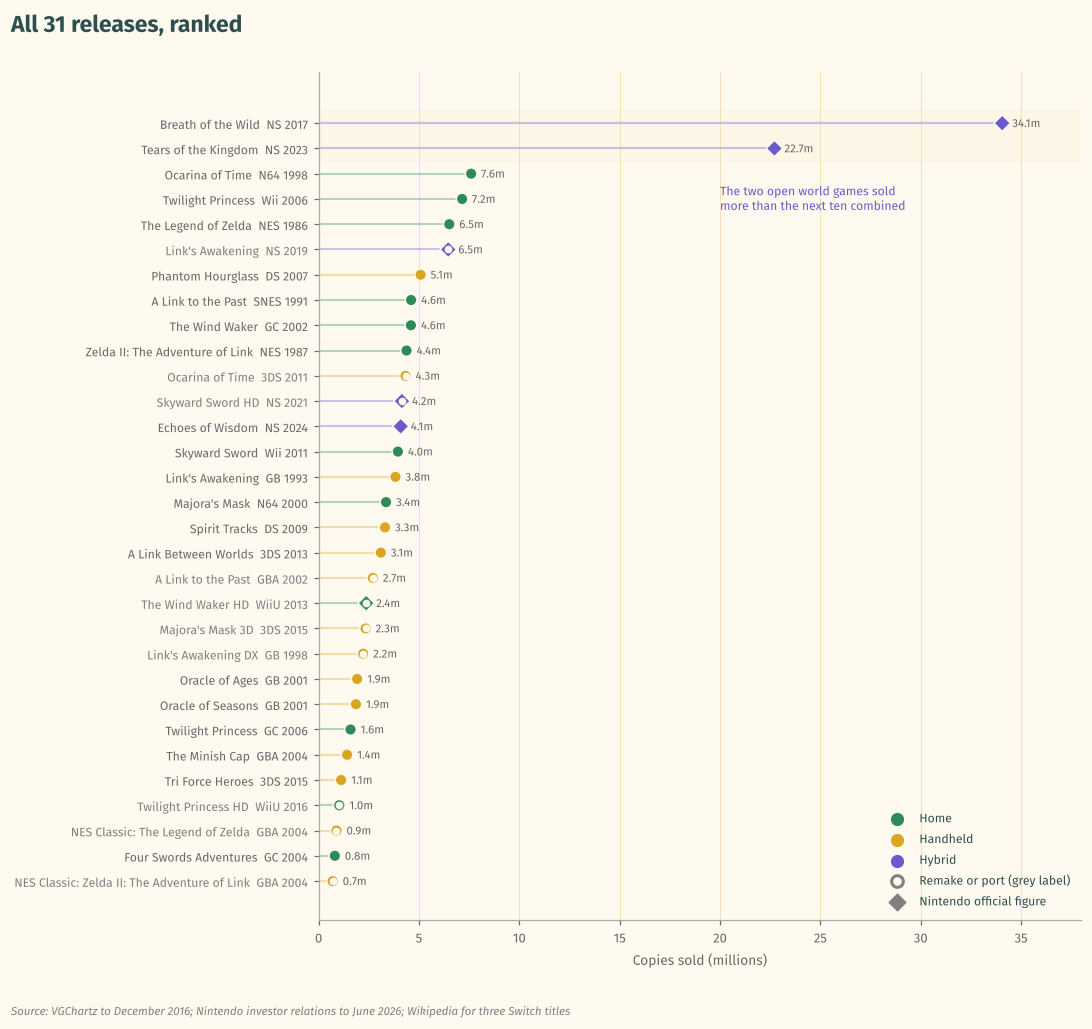

Top two: 56.8m, next ten: 54.9m


In [16]:
#| label: fig-dots
#| fig-cap: "**Every release, ranked.** 31 releases on an axis starting at zero. Diamonds are Nintendo figures, circles VGChartz estimates."
z = zelda.sort_values("units_m").reset_index(drop=True)
colors = z["type"].map(TYPE_COLORS)
official_rows = z["source"].str.startswith("Nintendo")
fig, ax = plt.subplots(figsize=(10, 9.4))
ax.axhspan(len(z) - 2.5, len(z) - 0.5, color="oldlace", zorder=0)
ax.hlines(z.index, 0, z["units_m"], color=colors, linewidth=1.4, alpha=0.35)
for marker, rows in [("o", ~official_rows), ("D", official_rows)]:
    sub = z[rows]
    ax.scatter(sub["units_m"], sub.index, marker=marker, s=58, color=sub["type"].map(TYPE_COLORS), edgecolor="floralwhite", linewidth=1, zorder=3)
remake = z["kind"] == "Remake or port"
ax.scatter(z.loc[remake, "units_m"], z.index[remake], marker="o", s=16, color="floralwhite", zorder=4)
for i, row in z.iterrows():
    ax.text(row["units_m"] + 0.5, i, f"{row['units_m']:.1f}m", va="center", fontsize=7.5, color="dimgray")
labels = z["title"].str.replace("The Legend of Zelda: ", "").str.replace("Classic NES Series: ", "NES Classic: ")
ax.set_yticks(z.index)
ax.set_yticklabels(labels + "  " + z["code"] + " " + z["year"].astype(str), fontsize=8)
for tick, kind in zip(ax.get_yticklabels(), z["kind"]):
    if kind != "Original":
        tick.set_color("gray")
ax.text(20, len(z) - 3.4, "The two open world games sold\nmore than the next ten combined", fontsize=8, color="slateblue", va="top")
ax.set_xlim(0, 38)
ax.set_xlabel("Copies sold (millions)")
for name, color in TYPE_COLORS.items():
    ax.scatter([], [], s=58, color=color, label=name)
ax.scatter([], [], s=58, marker="o", facecolor="floralwhite", edgecolor="gray", linewidth=2, label="Remake or port (grey label)")
ax.scatter([], [], s=58, marker="D", color="gray", label="Nintendo official figure")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", color="wheat", linewidth=0.6)
ax.set_axisbelow(True)
frame(fig, "All 31 releases, ranked", "Copies sold per release on a zero based scale. Diamonds are Nintendo's own figures; circles are VGChartz estimates.", "VGChartz to December 2016; Nintendo investor relations to June 2026; Wikipedia for three Switch titles")
plt.show()
top2 = z["units_m"].iloc[-2:].sum()
next10 = z["units_m"].iloc[-12:-2].sum()
print(f"Top two: {top2:.1f}m, next ten: {next10:.1f}m")

Breath of the Wild and Tears of the Kingdom sold 56.8 million between them, more than the next ten releases combined (54.9 million). After them come home console originals: Ocarina of Time, Twilight Princess and the 1986 original. The best selling remake is Link's Awakening on Switch (6.5 million), and the best selling game on a dedicated handheld is Phantom Hourglass on the DS (5.1 million). Remakes hold up well. The 3DS Ocarina of Time sold 4.3 million, more than half the N64 original.

### Do reviews explain sales?

With 8,136 scored titles a normal scatter plot is just a grey blob, so the grey hexagons show how many titles fall in each spot. Nintendo games are green dots, Zelda games are gold, and the dark line is the median sales at each 5 point score band.

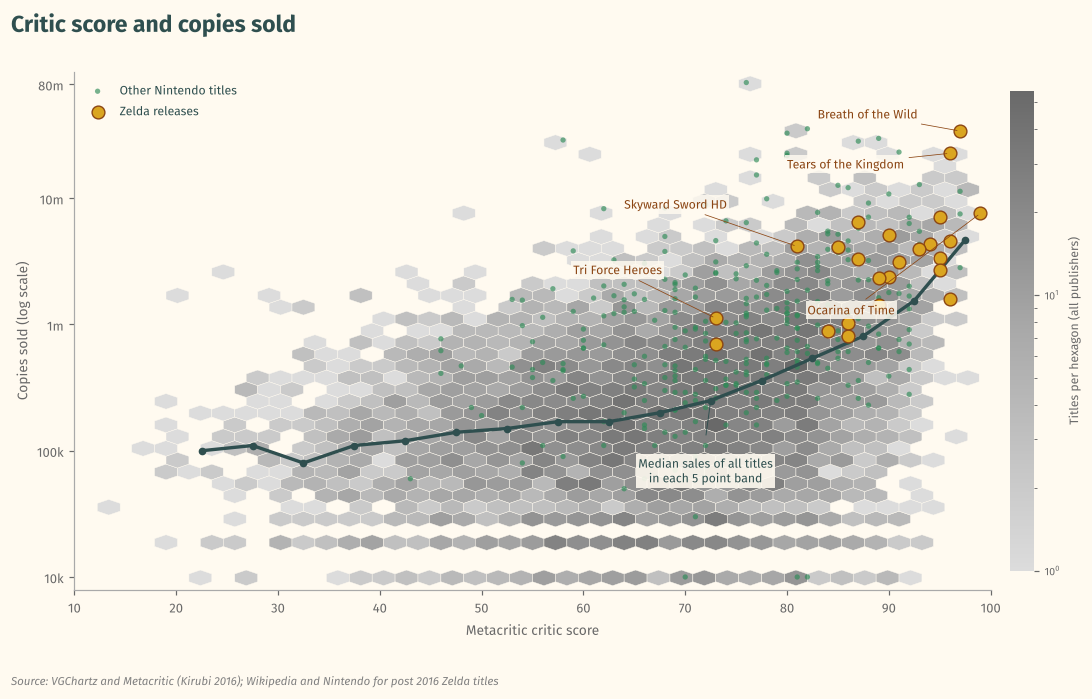

Spearman rho, all scored titles: 0.39 (n = 8,136)
Spearman rho, Zelda releases: 0.63 (n = 24)
bin
(20, 25]     0.10
(25, 30]     0.11
(30, 35]     0.08
(35, 40]     0.11
(40, 45]     0.12
(45, 50]     0.14
(50, 55]     0.15
(55, 60]     0.17
(60, 65]     0.17
(65, 70]     0.20
(70, 75]     0.25
(75, 80]     0.36
(80, 85]     0.54
(85, 90]     0.81
(90, 95]     1.54
(95, 100]    4.68


In [17]:
#| label: fig-scatter
#| fig-cap: "**Reviews and sales.** 8,136 scored titles. Spearman rho is 0.39 overall and 0.63 for the 24 scored Zelda releases."
pts = games.dropna(subset=["critic_score"])
pts = pts[pts["global_sales"] > 0]
fig, ax = plt.subplots(figsize=(10, 6.4))
greys = mcolors.LinearSegmentedColormap.from_list("greys", ["gainsboro", "darkgray", "dimgray"])
hexes = ax.hexbin(pts["critic_score"], np.log10(pts["global_sales"]), gridsize=(40, 22), extent=(10, 100, -2.1, 2), cmap=greys, mincnt=1, bins="log", linewidths=0.3, edgecolors="floralwhite")
bins = np.arange(20, 101, 5)
pts["bin"] = pd.cut(pts["critic_score"], bins)
med = pts.groupby("bin", observed=True)["global_sales"].median()
centres = [b.mid for b in med.index]
ax.plot(centres, np.log10(med.values), color=INK, linewidth=2.2, marker="o", markersize=4)
ax.text(72, -1.25, "Median sales of all titles\nin each 5 point band", fontsize=8, color=INK, ha="center", bbox=dict(facecolor="floralwhite", edgecolor="none", alpha=0.9, pad=1.5))
ax.annotate("", (72.5, np.log10(med.values[10])), xytext=(72, -0.9), arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.6))
nin_pts = pts[pts["nintendo"] & (pts["franchise"] != "Zelda")]
ax.scatter(nin_pts["critic_score"], np.log10(nin_pts["global_sales"]), s=12, color=NINTENDO, alpha=0.65, edgecolor="none", label="Other Nintendo titles")
zs = zelda.dropna(subset=["score"])
ax.scatter(zs["score"], np.log10(zs["units_m"]), s=70, color=ZELDA, edgecolor="saddlebrown", linewidth=0.9, zorder=4, label="Zelda releases")
notes = {("The Legend of Zelda: Breath of the Wild", "NS"): (-14, 0.1), ("The Legend of Zelda: Tears of the Kingdom", "NS"): (-16, -0.12), ("The Legend of Zelda: Ocarina of Time", "N64"): (-17, -0.8), ("The Legend of Zelda: Tri Force Heroes", "3DS"): (-14, 0.35), ("The Legend of Zelda: Skyward Sword HD", "NS"): (-17, 0.3)}
for row in zs.itertuples():
    key = (row.title, row.code)
    if key in notes:
        dx, dy = notes[key]
        ax.annotate(row.title.replace("The Legend of Zelda: ", ""), (row.score, np.log10(row.units_m)), xytext=(row.score + dx, np.log10(row.units_m) + dy), fontsize=8, color="saddlebrown", zorder=6, bbox=dict(facecolor="floralwhite", edgecolor="none", alpha=0.85, pad=1.2), arrowprops=dict(arrowstyle="-", color="saddlebrown", linewidth=0.5))
ax.set_yticks(np.log10(SALES_TICKS))
ax.set_yticklabels(SALES_LABELS)
ax.set_xlim(10, 100)
ax.set_ylim(-2.1, 2)
ax.set_xlabel("Metacritic critic score")
ax.set_ylabel("Copies sold (log scale)")
bar = fig.colorbar(hexes, ax=ax, fraction=0.025, pad=0.02)
bar.set_label("Titles per hexagon (all publishers)", fontsize=8)
bar.outline.set_visible(False)
bar.ax.tick_params(labelsize=7)
ax.legend(loc="upper left", fontsize=8)
frame(fig, "Critic score and copies sold", "Every scored title as a hexagon density, with Nintendo and Zelda titles on top and the median sales line for each 5 point score band.", "VGChartz and Metacritic (Kirubi 2016); Wikipedia and Nintendo for post 2016 Zelda titles")
plt.show()
rho_all = pts["critic_score"].corr(pts["global_sales"], method="spearman")
rho_z = zs["score"].corr(zs["units_m"], method="spearman")
print(f"Spearman rho, all scored titles: {rho_all:.2f} (n = {len(pts):,})")
print(f"Spearman rho, Zelda releases: {rho_z:.2f} (n = {len(zs)})")
print(med.round(2).to_string())

Better reviewed games sell more, but loosely. The rank correlation (Spearman) is 0.39 across all scored titles and 0.63 across the 24 scored Zelda releases. The median line stays under 200,000 copies up to a score of 70 and then climbs fast; games scoring 95 or more have a median of 4.7 million. Still, Ocarina of Time and Breath of the Wild both scored 97 or higher, and Breath of the Wild sold more than four times as much. How many people own the console matters too, which is what the console ratio in the next part looks at.

## Regions and consoles

### Reshaping regional sales

The sales file has one column per region. `melt` turns it into a long table with one row per title and region, which is easier to group. I keep Nintendo's titles and split them at 2006, when the Wii and the DS Lite came out in the West.

In [18]:
nin = games[games["nintendo"] & games["year"].notna()].copy()
nin["era"] = np.where(nin["year"] < 2006, "1983 to 2005", "2006 to 2016")
regional = nin.melt(id_vars=["name", "platform", "year", "era", "franchise"], value_vars=["na_sales", "eu_sales", "jp_sales", "other_sales"], var_name="region", value_name="units_m")
regional["region"] = regional["region"].str.replace("_sales", "").str.upper()
print(regional.shape)
regional.head()

(2788, 7)


,name,platform,year,era,franchise,region,units_m
0,Wii Sports,Wii,2006,2006 to 2016,Other Nintendo,NA,41.36
1,Super Mario Bros.,NES,1985,1983 to 2005,Mario,NA,29.08
2,Mario Kart Wii,Wii,2008,2006 to 2016,Mario,NA,15.68
3,Wii Sports Resort,Wii,2009,2006 to 2016,Other Nintendo,NA,15.61
4,Pokemon Red/Pokemon Blue,GB,1996,1983 to 2005,Pokemon,NA,11.27


Dividing each franchise's regional sales by its total for the era gives regional shares.

In [19]:
keep = ["Zelda", "Mario", "Pokemon", "Donkey Kong", "Kirby", "Metroid", "Fire Emblem"]
by_era = regional[regional["franchise"].isin(keep)].groupby(["franchise", "era", "region"], as_index=False)["units_m"].sum()
by_era["share"] = by_era["units_m"] / by_era.groupby(["franchise", "era"])["units_m"].transform("sum")
wide = by_era.pivot_table(index=["franchise", "era"], columns="region", values="share").round(2)
wide

region                      EU    JP    NA  OTHER
franchise   era                                  
Donkey Kong 1983 to 2005  0.17  0.31  0.49   0.03
            2006 to 2016  0.29  0.18  0.45   0.07
Fire Emblem 1983 to 2005  0.10  0.62  0.28   0.01
            2006 to 2016  0.15  0.34  0.45   0.06
Kirby       1983 to 2005  0.07  0.50  0.41   0.02
            2006 to 2016  0.08  0.41  0.46   0.05
Mario       1983 to 2005  0.18  0.24  0.55   0.03
            2006 to 2016  0.29  0.19  0.45   0.08
Metroid     1983 to 2005  0.18  0.21  0.59   0.03
            2006 to 2016  0.24  0.07  0.60   0.09
Pokemon     1983 to 2005  0.25  0.30  0.41   0.04
            2006 to 2016  0.23  0.33  0.37   0.06
Zelda       1983 to 2005  0.21  0.22  0.55   0.03
            2006 to 2016  0.30  0.13  0.48   0.08

### Has Zelda left Japan behind?

Four panels, one per region, on the same scale. The hollow dot is a franchise's share before 2006 and the filled dot its share after.

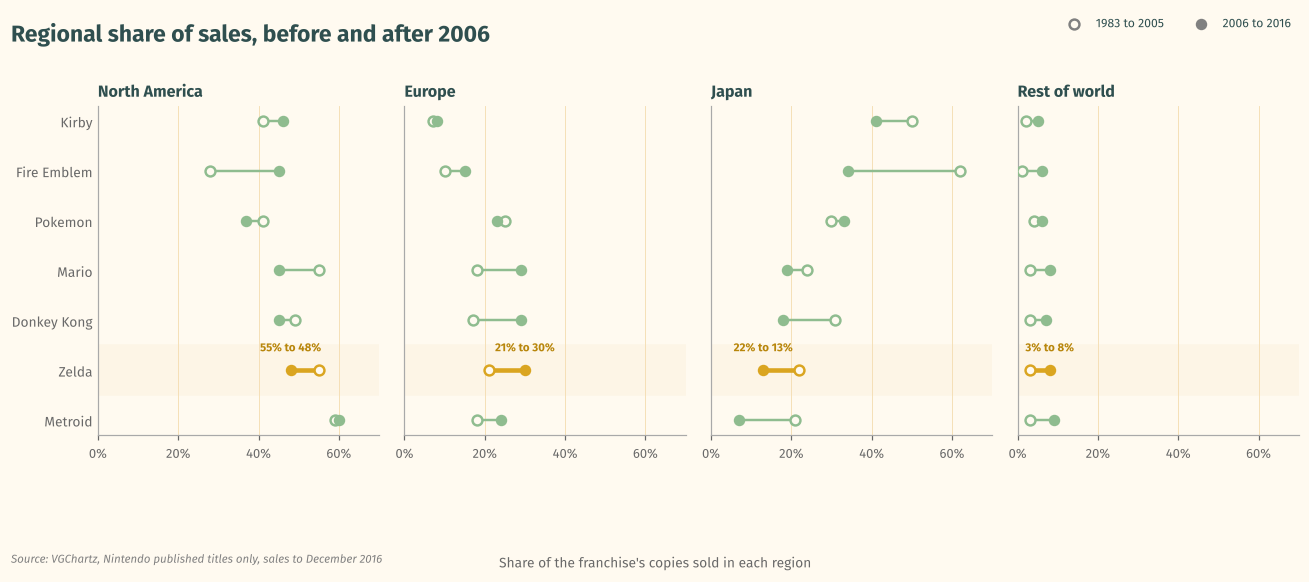

In [20]:
#| label: fig-dumbbell
#| fig-cap: "**Regional shares.** Seven Nintendo franchises, 1983 to 2005 against 2006 to 2016, on one shared 0 to 70 percent scale."
regions = {"NA": "North America", "EU": "Europe", "JP": "Japan", "OTHER": "Rest of world"}
order = wide["JP"].unstack("era").sort_values("2006 to 2016").index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(12, 5.2), sharey=True)
for ax, (code, label) in zip(axes, regions.items()):
    data = wide[code].unstack("era").loc[order]
    for i, name in enumerate(order):
        before = data.loc[name, "1983 to 2005"]
        after = data.loc[name, "2006 to 2016"]
        color = ZELDA if name == "Zelda" else "darkseagreen"
        ax.plot([before, after], [i, i], color=color, linewidth=3 if name == "Zelda" else 1.6, solid_capstyle="round", zorder=2)
        ax.scatter(before, i, s=42, facecolor="floralwhite", edgecolor=color, linewidth=1.6, zorder=3)
        ax.scatter(after, i, s=42, color=color, zorder=3)
        if name == "Zelda":
            ax.text(after, i + 0.38, f"{before:.0%} to {after:.0%}", ha="center", fontsize=7.5, color="darkgoldenrod", fontweight="bold")
    ax.axhspan(order.index("Zelda") - 0.5, order.index("Zelda") + 0.5, color="oldlace", zorder=0)
    ax.set_title(label, loc="left", fontsize=10.5, fontweight="bold", color=INK)
    ax.set_xlim(0, 0.7)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.grid(axis="x", color="wheat", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order, fontsize=9)
axes[0].scatter([], [], s=42, facecolor="floralwhite", edgecolor="gray", linewidth=1.6, label="1983 to 2005")
axes[0].scatter([], [], s=42, color="gray", label="2006 to 2016")
fig.legend(loc="upper right", bbox_to_anchor=(0.99, 1.0), ncol=2, fontsize=8)
fig.supxlabel("Share of the franchise's copies sold in each region", fontsize=9, color="dimgray")
frame(fig, "Regional share of sales, before and after 2006", "Share of each franchise's copies sold in each region, before and after 2006. Franchises sorted by their Japanese share after 2006.", "VGChartz, Nintendo published titles only, sales to December 2016", foot=0.6)
plt.show()

Japan's share of Zelda sales dropped from 22 percent before 2006 to 13 percent after. Europe went up from 21 to 30 percent and the rest of the world from 3 to 8, while North America slipped from 55 to 48. Metroid dropped even more in Japan (21 to 7 percent). Pokemon went the other way (30 to 33), and Kirby still sold 41 percent of its copies in Japan.

### The Triforce of regions

A ternary plot shows a three way split in a triangle. Each corner is a region, and a point moves away from a corner when that region's share falls. I leave out the small "rest of world" share and rescale the other three to 100 percent. Each arrow goes from a franchise's split before 2006 to its split after.

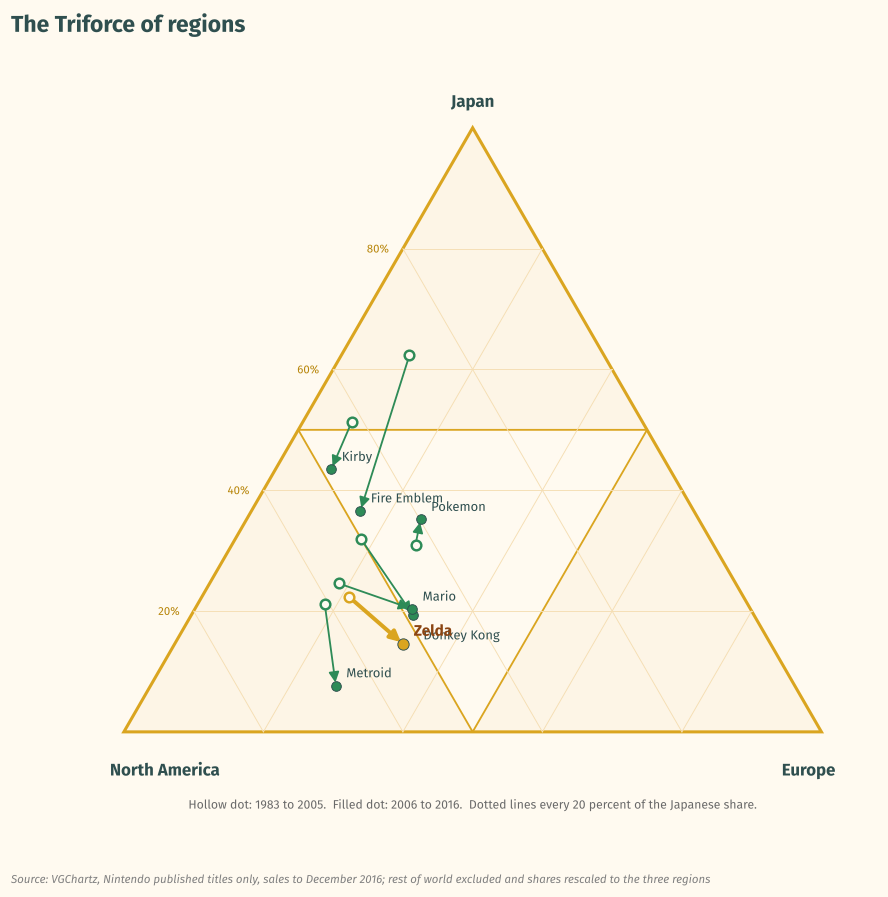

region,franchise,era,EU,JP,NA,x,y
0,Donkey Kong,1983 to 2005,0.18,0.32,0.50,0.34,0.28
1,Donkey Kong,2006 to 2016,0.32,0.19,0.49,0.41,0.17
2,Fire Emblem,1983 to 2005,0.10,0.62,0.28,0.41,0.54
3,Fire Emblem,2006 to 2016,0.16,0.37,0.48,0.34,0.32
4,Kirby,1983 to 2005,0.07,0.51,0.42,0.33,0.44
5,Kirby,2006 to 2016,0.08,0.43,0.49,0.30,0.38
6,Mario,1983 to 2005,0.19,0.25,0.57,0.31,0.21
7,Mario,2006 to 2016,0.31,0.20,0.48,0.41,0.18
8,Metroid,1983 to 2005,0.18,0.21,0.61,0.29,0.18
9,Metroid,2006 to 2016,0.27,0.08,0.66,0.30,0.07


In [21]:
#| label: fig-triforce
#| fig-cap: "**The Triforce of regions.** North America, Europe and Japan rescaled to 100 percent; rest of world left out."
tri = by_era[by_era["region"].isin(["NA", "EU", "JP"])].copy()
tri["share"] = tri["units_m"] / tri.groupby(["franchise", "era"])["units_m"].transform("sum")
tri = tri.pivot_table(index=["franchise", "era"], columns="region", values="share").reset_index()
tri["x"] = tri["EU"] + tri["JP"] / 2
tri["y"] = tri["JP"] * np.sqrt(3) / 2
h = np.sqrt(3) / 2
fig, ax = plt.subplots(figsize=(8.6, 8.2))
ax.add_patch(Polygon([(0, 0), (1, 0), (0.5, h)], closed=True, facecolor="oldlace", edgecolor="goldenrod", linewidth=2))
ax.add_patch(Polygon([(0.25, h / 2), (0.75, h / 2), (0.5, 0)], closed=True, facecolor="floralwhite", edgecolor="goldenrod", linewidth=1.2))
for k in [0.2, 0.4, 0.6, 0.8]:
    ax.plot([k / 2, 1 - k / 2], [k * h, k * h], color="wheat", linewidth=0.6, zorder=1)
    ax.plot([k, k / 2 + 0.5], [0, (1 - k) * h], color="wheat", linewidth=0.6, zorder=1)
    ax.plot([k, k / 2], [0, k * h], color="wheat", linewidth=0.6, zorder=1)
    ax.text(k / 2 - 0.02, k * h, f"{k:.0%}", fontsize=7.5, color="darkgoldenrod", ha="right", va="center")
for name, group in tri.groupby("franchise"):
    before = group[group["era"] == "1983 to 2005"].iloc[0]
    after = group[group["era"] == "2006 to 2016"].iloc[0]
    color = ZELDA if name == "Zelda" else "seagreen"
    width = 2.6 if name == "Zelda" else 1.2
    ax.annotate("", (after["x"], after["y"]), xytext=(before["x"], before["y"]), arrowprops=dict(arrowstyle="-|>", color=color, linewidth=width, mutation_scale=14), zorder=4)
    ax.scatter(before["x"], before["y"], s=40, facecolor="floralwhite", edgecolor=color, linewidth=1.6, zorder=5)
    ax.scatter(after["x"], after["y"], s=55 if name == "Zelda" else 40, color=color, edgecolor=INK, linewidth=0.6, zorder=5)
    nudge = {"Donkey Kong": -0.035, "Mario": 0.012}.get(name, 0.012)
    ax.text(after["x"] + 0.015, after["y"] + nudge, name, fontsize=8.5 if name != "Zelda" else 10, color="saddlebrown" if name == "Zelda" else INK, fontweight="bold" if name == "Zelda" else "normal", zorder=6)
ax.text(0.5, h + 0.03, "Japan", ha="center", fontsize=11, fontweight="bold", color=INK)
ax.text(-0.02, -0.04, "North America", ha="left", va="top", fontsize=11, fontweight="bold", color=INK)
ax.text(1.02, -0.04, "Europe", ha="right", va="top", fontsize=11, fontweight="bold", color=INK)
ax.text(0.5, -0.11, "Hollow dot: 1983 to 2005.  Filled dot: 2006 to 2016.  Dotted lines every 20 percent of the Japanese share.", ha="center", fontsize=8, color="dimgray")
ax.set_xlim(-0.08, 1.08)
ax.set_ylim(-0.15, h + 0.08)
ax.set_aspect("equal")
ax.set_axis_off()
frame(fig, "The Triforce of regions", "Each franchise's sales split between North America, Europe and Japan, before and after 2006.\nA point moves away from a corner as that region's share falls.", "VGChartz, Nintendo published titles only, sales to December 2016; rest of world excluded and shares rescaled to the three regions", head=1.15)
plt.show()
tri.round(2)

Six of the seven arrows point down, away from Japan, and those six all gained European share. Zelda went from 57, 21 and 22 percent (North America, Europe, Japan) to 53, 33 and 15. Fire Emblem moved the most, from 62 percent Japanese to 37. Pokemon is the only one moving toward Japan (31 to 35 percent).

### Zelda copies per console

To answer the title question I divide the Zelda copies sold on each console by the number of consoles Nintendo sold. The Switch 2 drops out, since it has no Zelda original yet (and Nintendo counts the Switch 2 Editions of Breath of the Wild and Tears of the Kingdom as Switch 2 sales).

::: {.callout-warning title="Attention" collapse="false"}
The 3DS and Wii U ratios are too low: their VGChartz Zelda numbers stop in 2016, but their hardware totals run to 2026.
:::

In [22]:
per_platform = zelda.groupby("code", as_index=False).agg(zelda_units=("units_m", "sum"), releases=("title", "count"))
per_platform = per_platform.merge(platforms, on="code", how="inner")
per_platform["per_100"] = per_platform["zelda_units"] / per_platform["hardware_m"] * 100
per_platform = per_platform.sort_values("launch_year")
per_platform[["platform", "code", "type", "launch_year", "releases", "zelda_units", "hardware_m", "per_100"]].round(1)

,platform,code,type,launch_year,releases,zelda_units,hardware_m,per_100
6,Family Computer/NES,NES,Home,1983,2,10.9,61.9,17.6
2,Game Boy,GB,Handheld,1989,4,9.8,118.7,8.3
8,Super Famicom/SNES,SNES,Home,1990,1,4.6,49.1,9.4
5,Nintendo 64,N64,Home,1996,2,11.0,32.9,33.3
4,Nintendo GameCube,GC,Home,2001,3,7.0,21.7,32.2
3,Game Boy Advance,GBA,Handheld,2001,4,5.7,81.5,7.0
1,Nintendo DS,DS,Handheld,2004,2,8.4,154.0,5.4
9,Wii,Wii,Home,2006,2,11.1,101.6,10.9
0,Nintendo 3DS,3DS,Handheld,2011,4,10.9,75.9,14.3
10,Wii U,WiiU,Home,2012,2,3.4,13.6,25.1


### A misleading chart, revised

This was my first platform chart. The bars are in alphabetical order, every bar has a random colour, the y axis starts at 3 million so the Wii U almost disappears, and it uses raw totals. The last one is the real problem: the Switch sold 156.6 million consoles and the Wii U 13.6 million, so the Switch bar mostly shows how many people own a Switch.

::: {.callout-warning title="Attention" collapse="false"}
This is the bad first draft, kept on purpose.
:::

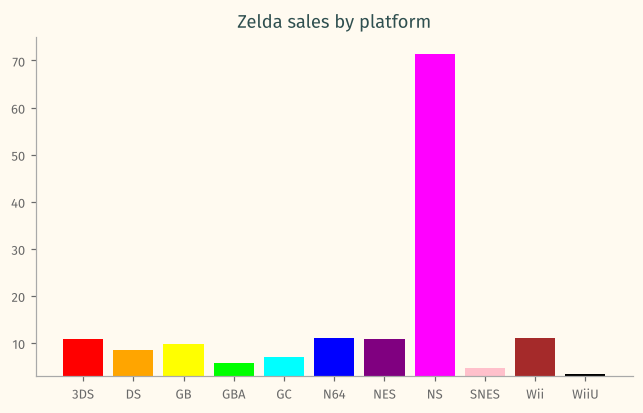

In [23]:
#| label: fig-before
#| fig-cap: "**Platform totals, first draft.** Kept on purpose: alphabetical order, colours that encode nothing, an axis starting at 3 million and raw totals."
alpha = per_platform.sort_values("code")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(alpha["code"], alpha["zelda_units"], color=["red", "orange", "yellow", "lime", "cyan", "blue", "purple", "magenta", "pink", "brown", "black"])
ax.set_ylim(3, 75)
ax.set_title("Zelda sales by platform")
plt.show()

The fix divides Zelda copies by consoles sold. Each grid is 100 consoles and each coloured square is one Zelda copy, sorted from highest to lowest, with the raw numbers printed so the division can be checked.

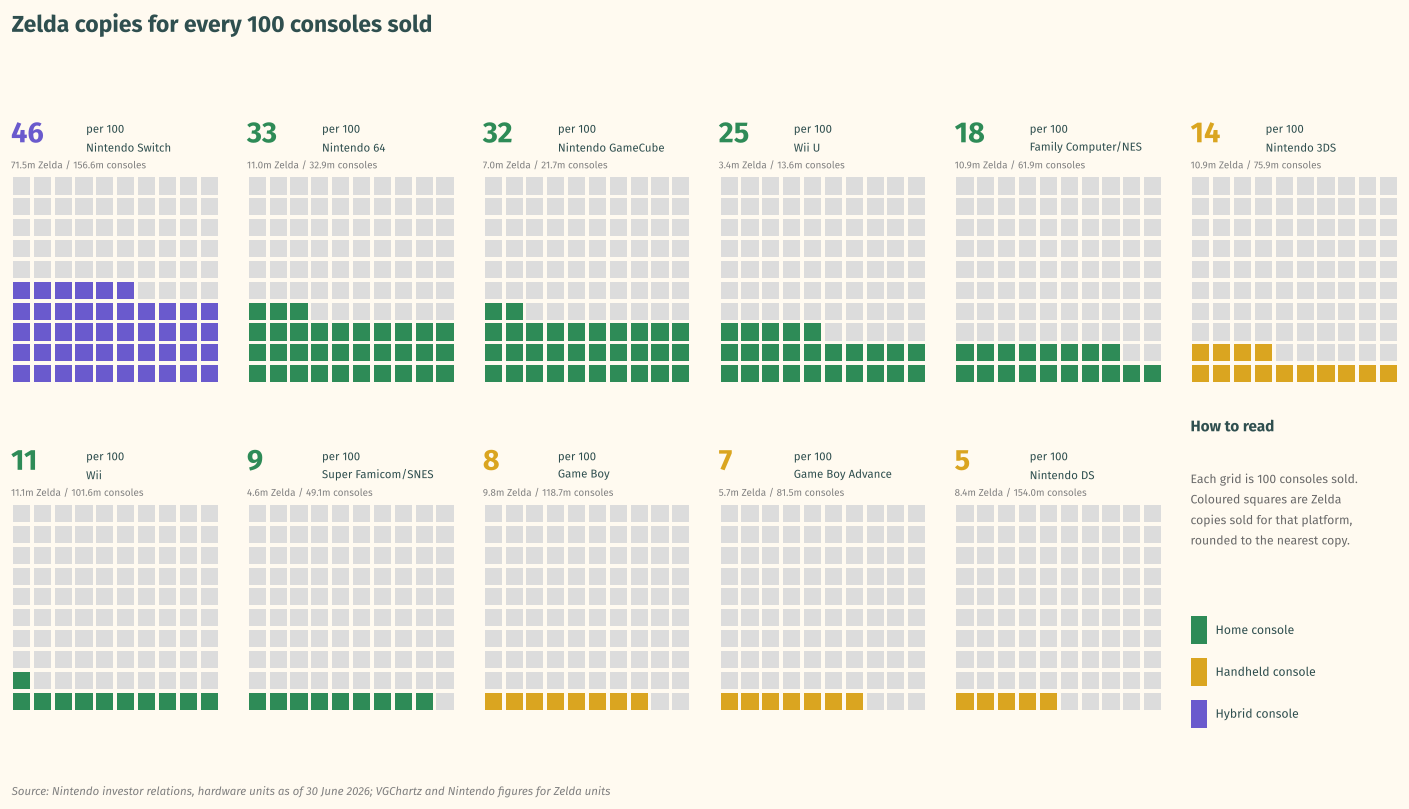

In [24]:
#| label: fig-after
#| fig-cap: "**Zelda copies per 100 consoles.** 11 platforms. Hardware to 30 June 2026; 3DS and Wii U ratios are lower bounds."
ranked = per_platform.sort_values("per_100", ascending=False).reset_index(drop=True)
fig, axes = plt.subplots(2, 6, figsize=(13, 7.4))
for ax, row in zip(axes.flat, ranked.itertuples()):
    filled = int(round(row.per_100))
    for k in range(100):
        x = k % 10
        y = k // 10
        color = TYPE_COLORS[row.type] if k < filled else "gainsboro"
        ax.add_patch(Rectangle((x + 0.09, y + 0.09), 0.82, 0.82, facecolor=color, edgecolor="none"))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 13.2)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.text(0, 12.9, f"{row.per_100:.0f}", fontsize=19, fontweight="bold", color=TYPE_COLORS[row.type], va="top")
    ax.text(3.6, 12.6, f"per 100\n{row.platform}", fontsize=7.5, color=INK, va="top", linespacing=1.25)
    ax.text(0, 10.35, f"{row.zelda_units:.1f}m Zelda / {row.hardware_m:.1f}m consoles", fontsize=6.5, color="gray")
key = axes.flat[-1]
key.set_axis_off()
key.text(0, 0.95, "How to read", fontsize=10, fontweight="bold", color=INK, va="top", transform=key.transAxes)
key.text(0, 0.8, "Each grid is 100 consoles sold.\nColoured squares are Zelda\ncopies sold for that platform,\nrounded to the nearest copy.", fontsize=8, color="dimgray", va="top", linespacing=1.4, transform=key.transAxes)
for i, (name, color) in enumerate(TYPE_COLORS.items()):
    key.add_patch(Rectangle((0, 0.3 - i * 0.12), 0.08, 0.08, facecolor=color, transform=key.transAxes))
    key.text(0.12, 0.34 - i * 0.12, name + " console", fontsize=8, va="center", color=INK, transform=key.transAxes)
frame(fig, "Zelda copies for every 100 consoles sold", "Platforms sorted from the highest ratio to the lowest. The Switch leads, but the N64 and GameCube come close with a fraction of its audience.", "Nintendo investor relations, hardware units as of 30 June 2026; VGChartz and Nintendo figures for Zelda units", head=1.0)
plt.show()

This answers the third question. The Switch leads with 46 Zelda copies per 100 consoles, but the Nintendo 64 (33) and GameCube (32) are close behind with much smaller audiences. Even the Wii U, Nintendo's weakest seller, reaches 25. The three lowest are handhelds, with the DS last at 5. The DS sold 154 million units, and its biggest games were New Super Mario Bros. (29.8 million), Nintendogs (24.7 million) and Mario Kart DS (23.2 million). The Wii (11) is low for a similar reason: its audience bought Wii Sports and Wii Play. The raw totals chart had the Wii U last; per console it is fourth.

## Conclusions

### Findings

The first answer is that Zelda games sell far above the industry norm. The median Zelda title sold 2.9 million copies, 17 times the median game in the file, and no Zelda title sold fewer than 700,000. For thirty years that strength stayed inside a narrow band, with no original from 1986 to 2015 passing 7.6 million, until Breath of the Wild sold 34.1 million and Tears of the Kingdom 22.7 million on the Switch.

The audience behind those numbers moved west. Japan's share of Zelda sales fell from 22 to 13 percent after 2006, while Pokemon's Japanese share went up to 33 percent and Kirby still sold 41 percent of its copies in Japan. Zelda became a series bought mostly in North America and Europe.

On the title question, Zelda sells the highest share of consoles with smaller, dedicated audiences. The top five ratios are the Switch (46 per 100), the Nintendo 64, the GameCube, the Wii U and the NES (18). Every handheld is at 14 or below, and the two mass market consoles, the DS and the Wii, sit at 5 and 11. Their biggest games were New Super Mario Bros. and Nintendogs on the DS and Wii Sports on the Wii.

An obvious next step would be to swap the VGChartz estimates for Nintendo's official numbers wherever they exist, and to add the Switch 2 Edition sales once Nintendo publishes them.

### Limits

The VGChartz numbers are estimates, leave out digital sales, and stop in 2016, so the pre 2017 Zelda figures are low and the regional analysis ends in 2016. Nintendo only publishes figures for its biggest sellers, which is why three Switch numbers come from Wikipedia with different dates. The Switch 2 Editions of Breath of the Wild and Tears of the Kingdom are not in the data at all. Only 14 of the 20 originals have a Metacritic score. And copies per console is not the same as the share of owners who bought a Zelda game, since one person can buy several.

### Reflection

The hardest part was deciding which numbers to trust. VGChartz is the only open dataset with regional sales for thousands of games, but its numbers are estimates, end in 2016 and skip digital sales. Nintendo's figures are official but only cover the top ten games per console. I used both and labelled every row with its source. Comparing the two on The Wind Waker HD (1.79 million against 2.37 million) showed me how big the gap can be. Smaller things took time too: 2,425 user scores stored as "tbd", 20 partial "weekly sales" rows, Link's Awakening dated a year early, and a Wii U remake filed under the GameCube title, which broke my first join. I checked the name matching by making sure the two score sources agreed on the 15 games they share.

Most of my design choices came from the perception readings. Sales cover four orders of magnitude, so every sales axis is on a log scale. I tried overlapping histograms for the franchises first, but eight of them on one plot were unreadable, so I switched to a ridgeline. For critic scores I drew the raw points under the density because a box plot hid how few Zelda games there are. The hexbin fixes overplotting in the scatter. I kept gold for Zelda in every chart so the reader only has to learn the colours once.

The platform chart is where the design changed the conclusion. My first version summed sales by platform, with rainbow colours and a cut off axis, and it made the Switch look dominant and the Wii U look irrelevant. Dividing by consoles sold moved the Wii U from last to fourth and showed the Nintendo 64 and GameCube close to the Switch.

The waffle chart communicates the main point best. It answers the title question directly, uses all three datasets, and you can count the squares without reading an axis.

## Credits {.appendix .unnumbered}

The notebook title uses **Triforce**, a fan made typeface modelled on the Zelda logo lettering, included in `fonts/`.

Chart and body text use **Fira Sans** by Erik Spiekermann, Ralph du Carrois and the Carrois type foundry for Mozilla, under the SIL Open Font Licence (`fonts/OFL.txt`).

## References {.appendix .unnumbered}

::: {.apa}
Kirubi, R. (2016). *Video game sales with ratings* [Data set]. Kaggle. VGChartz and Metacritic data as of 22 December 2016, mirrored at https://github.com/chahelgupta/DEP-videogames-dataset

The legend of Zelda. (2026). In *Wikipedia*. Retrieved October 22, 2026, from https://en.wikipedia.org/wiki/The_Legend_of_Zelda

List of best-selling Nintendo Switch video games. (2026). In *Wikipedia*. Retrieved October 22, 2026, from https://en.wikipedia.org/wiki/List_of_best-selling_Nintendo_Switch_video_games

Nintendo. (2017). *The legend of Zelda: Breath of the wild* [Video game]. Nintendo. In game view across Hyrule Field used, partly transparent, as the decorative banner above the title.

Nintendo Co., Ltd. (2026a). *Dedicated video game sales units* [Data set]. https://www.nintendo.co.jp/ir/en/finance/hard_soft/index.html

Nintendo Co., Ltd. (2026b). *Top selling title sales units* [Data set]. https://www.nintendo.co.jp/ir/en/finance/software/index.html
:::